# 01. Target Identification and Bioactivity Retrieval

**Goal:** Retrieve and clean Cyclin-dependent kinase 2 (CDK2) $IC_{50}$ screening data from ChEMBL using UniProt ID (`P24941`).


## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize

from chembl_webresource_client.new_client import new_client


RDLogger.DisableLog('rdApp.*')

HERE = Path.cwd()
DATA = HERE.parent / 'data'
FIGURES = HERE.parent / 'figures'
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

(DATA / 'raw').mkdir(exist_ok=True)
(DATA / 'processed').mkdir(exist_ok=True)

UNIPROT_ID = 'P24941'

print("Setup OK")

Setup OK


## 2. ChEMBL Target

In [2]:
target_api = new_client.target
target_query = target_api.get(target_components__accession=UNIPROT_ID).only(
    'target_chembl_id',
    'pref_name',
    'organism',
    'target_type'
)
# De-duplicate target records
target_df = pd.DataFrame(target_query).drop_duplicates(subset='target_chembl_id').reset_index(drop=True)
target_df

,organism,pref_name,target_chembl_id,target_type
0,Homo sapiens,Cyclin-dependent kinase 2,CHEMBL301,SINGLE PROTEIN
1,Homo sapiens,Cyclin-dependent kinase 2/cyclin E1,CHEMBL1907605,PROTEIN COMPLEX
2,Homo sapiens,Cyclin-dependent kinase 2/cyclin E,CHEMBL2094126,PROTEIN COMPLEX
3,Homo sapiens,Cyclin-dependent kinase 2/cyclin A,CHEMBL2094128,PROTEIN COMPLEX
4,Homo sapiens,Cyclin-dependent kinase 2 and 4 (CDK2 and CDK4),CHEMBL2111326,SELECTIVITY GROUP
5,Homo sapiens,CDK2/Cyclin A2,CHEMBL3038469,PROTEIN COMPLEX
6,Homo sapiens,CDK2/Cyclin A1,CHEMBL3038470,PROTEIN COMPLEX
7,Homo sapiens,CDK2/CDK4,CHEMBL3038517,PROTEIN FAMILY
8,Homo sapiens,Cyclin-dependent kinase,CHEMBL3559691,PROTEIN FAMILY
9,Homo sapiens,Cyclin-dependent kinase 2/G1/S-specific cyclin-D1,CHEMBL3885552,PROTEIN COMPLEX


## 3. Retrieve Bioactivity Data

In [3]:
# Curation Log
curated_log = []

def log(df, name, condition=None):
    """
    Filters the dataframe based on a condition and records row & molecule stats.
    """
    if condition is not None:
        df = df[condition].copy()

    curated_log.append({
        'name': name,
        'records': len(df),
        'molecules': df['molecule_chembl_id'].nunique()
    })
    return df
    
# Target ID 
TARGET_ID = 'CHEMBL301'

# Retrieve Activities
activity_api = new_client.activity
chembl_activities = activity_api.filter(
    target_chembl_id=TARGET_ID,
    standard_type='IC50',
    standard_units='nM',
    standard_relation='=',
    assay_type='B',
).only([
    'activity_id', 'molecule_chembl_id', 'canonical_smiles',
    'standard_type', 'standard_units', 'standard_value',
    'assay_chembl_id',
])

activity_df = pd.DataFrame.from_records(chembl_activities)

# Retrieve Assays for Confidence Score
assay_df = pd.DataFrame.from_records(new_client.assay.filter(
    target_chembl_id=TARGET_ID,
    assay_type='B',
).only(['assay_chembl_id', 'confidence_score', 'description']))

# Merge and Log baseline raw counts
chembl_df = activity_df.merge(assay_df, on='assay_chembl_id', how='left')
chembl_df = chembl_df.drop_duplicates(subset='activity_id')

chembl_df.to_csv(DATA / 'raw' / 'chembl_cdk2_raw.csv', index=False)

chembl_df = log(chembl_df, 'Raw ChEMBL download')
chembl_df.head()

,activity_id,assay_chembl_id,canonical_smiles,molecule_chembl_id,standard_type,standard_units,standard_value,type,units,value,confidence_score,description
0,105376,CHEMBL660784,COc1ccc(Nc2ccnc(Nc3ccc(OCC(O)CN(C)C)cc3)n2)cc1,CHEMBL101052,IC50,nM,36000.0,IC50,uM,36.0,8,Inhibitory concentration against cyclin-depend...
2,106512,CHEMBL661128,O=C(Nc1n[nH]c2nc(-c3ccc(O)c(Br)c3)ccc12)C1CC1,CHEMBL260416,IC50,nM,2.0,IC50,nM,2.0,8,Inhibitory concentration against cyclin-depend...
3,108039,CHEMBL661130,CC(C)C(CO)Nc1nc(NCc2cccc(O)c2)c2ncn(C(C)C)c2n1,CHEMBL84944,IC50,nM,30.0,IC50,uM,0.03,9,Inhibition of Cyclin-dependent kinase 2
4,108796,CHEMBL660784,CN(C)CC(O)COc1ccc(Nc2ncc(Br)c(N(CCCC(F)(F)F)c3...,CHEMBL419720,IC50,nM,200.0,IC50,uM,0.2,8,Inhibitory concentration against cyclin-depend...
5,108798,CHEMBL661128,O=C(Nc1n[nH]c2cc(-c3ccc[nH]3)ccc12)C1CC1,CHEMBL260929,IC50,nM,497.0,IC50,nM,497.0,8,Inhibitory concentration against cyclin-depend...


In [4]:
chembl_df.info()

<class 'pandas.DataFrame'>
Index: 2763 entries, 0 to 2795
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   activity_id         2763 non-null   int64
 1   assay_chembl_id     2763 non-null   str  
 2   canonical_smiles    2759 non-null   str  
 3   molecule_chembl_id  2763 non-null   str  
 4   standard_type       2763 non-null   str  
 5   standard_units      2763 non-null   str  
 6   standard_value      2763 non-null   str  
 7   type                2763 non-null   str  
 8   units               2682 non-null   str  
 9   value               2763 non-null   str  
 10  confidence_score    2763 non-null   int64
 11  description         2763 non-null   str  
dtypes: int64(2), str(10)
memory usage: 1.5 MB


In [5]:
chembl_df.nunique()

activity_id           2763
assay_chembl_id        365
canonical_smiles      2104
molecule_chembl_id    2106
standard_type            1
standard_units           1
standard_value        1097
type                     3
units                    3
value                 1166
confidence_score         2
description            193
dtype: int64

## 4. Data Filtering
* Handling Missing Values
* Numeric Type Conversion
* Confidence Threshold: scores ($\geq 8$) retains assays assigned directly to CDK2 (score 9) or to a homologous single protein (score 8).


In [6]:
# Strip invalid entries/columns
df = chembl_df.dropna(subset=['standard_units', 'standard_value', 'canonical_smiles']).copy()
df = df.drop(['units', 'value', 'type'], axis=1, errors='ignore')
df = log(df, 'Valid measurements present')

# Filter positive numeric entries
df['standard_value'] = pd.to_numeric(df['standard_value'], errors='coerce')
df = log(df, 'Positive numeric value', df['standard_value'] > 0)

# Binding confidence filtering
df = log(df, 'Confidence score >= 8', df['confidence_score'] >= 8)
df.confidence_score.value_counts()

confidence_score
9    1425
8    1334
Name: count, dtype: int64

## 5. Standardization
* **Molecular Standardization Pipeline**
Enforced to ensure structural uniformity:
    1. **Salt Stripping:** `LargestFragmentChooser` isolates active organic core.
    2. **Neutralization:** `Uncharger` removes variable formal charges.
    3. **Tautomer Canonicalization:** `TautomerEnumerator` resolves tautomeric forms to a single representation.

In [7]:
# Molecular Standardization
chooser = rdMolStandardize.LargestFragmentChooser()
uncharger = rdMolStandardize.Uncharger()
te = rdMolStandardize.TautomerEnumerator()

def standardizer(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None
        mol = rdMolStandardize.Cleanup(mol)
        mol = chooser.choose(mol)
        mol = uncharger.uncharge(mol)
        mol = te.Canonicalize(mol)
    
        return Chem.MolToSmiles(mol, canonical=True)
    except Exception:
        return None

df['std_smiles'] = df['canonical_smiles'].apply(standardizer)
df = log(df, 'Standardized SMILES', df['std_smiles'].notna())

print(pd.DataFrame(curated_log).to_markdown(index=False))

| name                       |   records |   molecules |
|:---------------------------|----------:|------------:|
| Raw ChEMBL download        |      2763 |        2106 |
| Valid measurements present |      2759 |        2104 |
| Positive numeric value     |      2759 |        2104 |
| Confidence score >= 8      |      2759 |        2104 |
| Standardized SMILES        |      2759 |        2104 |


## 6. pIC50 & Duplicate Resolution
Compounds with identical `std_smiles` are aggregated by their **median value $pIC_{50}$** .
Entries with a spread $> 1.0$ log unit are  flagged as anomalies and removed.

In [8]:
# Convert IC50 thresholds (nM) to logarithmic pIC50 (M)
df['pIC50'] = 9 - np.log10(df['standard_value'])

agg_df = (df.groupby('std_smiles').agg(
    molecule_chembl_id=('molecule_chembl_id', lambda x: ';'.join(sorted(set(x)))),
    pIC50=('pIC50', 'median'),
    n_measurements=('pIC50', 'size'),
    pIC50_range=('pIC50', lambda x: x.max() - x.min()),
    activity_ids=('activity_id', lambda x: ';'.join(sorted(set(x.astype(str))))),
).reset_index())

# Flag records with variance >1
agg_df['high_variance'] = agg_df['pIC50_range'] > 1.0

agg_df.to_csv(DATA / 'processed' / 'cdk2_all_flagged.csv', index=False)
curated_log.append({
    'name': 'Aggregated by SMILES ',
    'records': len(agg_df),
    'molecules': agg_df['molecule_chembl_id'].nunique()
})

> **Note on Limitation:** The data mixes monomeric CDK2, CDK2/cyclin A, and CDK2/cyclin E assays in different formats.

## 7. Outlier Removal & Final Export

In [9]:
# Drop high variance molecules
final_df = agg_df[~agg_df['high_variance']].reset_index(drop=True)

final_df.to_csv(DATA / 'processed' / 'cdk2_curated.csv', index=False)
curated_log.append({
    'name': 'High-variance molecules removed',
    'records': len(final_df),
    'molecules': final_df['molecule_chembl_id'].nunique()
})

print(pd.DataFrame(curated_log).to_markdown(index=False))

| name                            |   records |   molecules |
|:--------------------------------|----------:|------------:|
| Raw ChEMBL download             |      2763 |        2106 |
| Valid measurements present      |      2759 |        2104 |
| Positive numeric value          |      2759 |        2104 |
| Confidence score >= 8           |      2759 |        2104 |
| Standardized SMILES             |      2759 |        2104 |
| Aggregated by SMILES            |      2085 |        2085 |
| High-variance molecules removed |      2044 |        2044 |


## 8. pIC50 Distribution Visualization

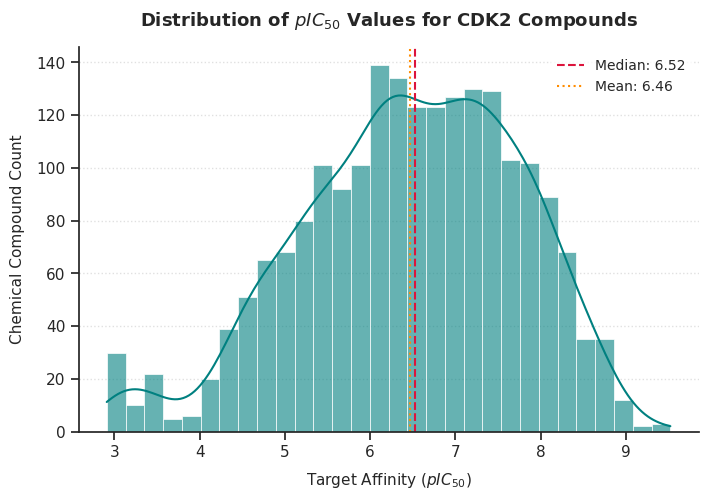

In [10]:
# pIC50 Distribution Plot

sns.set_theme(style='ticks')
plt.figure(figsize=(8, 5))

mean_val = final_df['pIC50'].mean()
median_val = final_df['pIC50'].median()
total_compounds = len(final_df)


sns.histplot(data=final_df, x='pIC50', bins=30, kde=True, color='teal', alpha=0.6, edgecolor='white', linewidth=0.5)

# Render statistical vertical lines
plt.axvline(median_val, color='crimson', linestyle='--', linewidth=1.5, label=f'Median: {median_val:.2f}')
plt.axvline(mean_val, color='darkorange', linestyle=':', linewidth=1.5, label=f'Mean: {mean_val:.2f}')

# Labels
plt.title('Distribution of $pIC_{50}$ Values for CDK2 Compounds', fontsize=13, fontweight='bold', pad=15)
plt.xlabel(r'Target Affinity ($pIC_{50}$)', fontsize=11, labelpad=8)
plt.ylabel('Chemical Compound Count', fontsize=11, labelpad=8)

sns.despine(top=True, right=True)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', fontsize=10)

plt.savefig(FIGURES / 'pIC50_distribution.png', dpi=300, bbox_inches='tight')
plt.show()